# Optimierer im Vergleich

Begleitnotebook zu [[gradientenabstieg-von-hand]], [[adam-adagrad-erster-schritt]] und [[optimierer-uebersicht]].
Testfunktion: schlecht konditionierte Quadratik $f(\theta) = (\theta_1 - 1)^2 + 10(\theta_2 + 2)^2$, Minimum bei $(1, -2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

f = lambda th: (th[0] - 1)**2 + 10 * (th[1] + 2)**2
grad = lambda th: np.array([2 * (th[0] - 1), 20 * (th[1] + 2)])
H = np.diag([2.0, 20.0])
theta0 = np.array([-3.0, 1.0])

## 1 · Lernrate in 1D: $f(\theta)=\theta^2$, $\theta_{t+1} = (1-2\eta)\theta_t$

In [2]:
for eta in [0.1, 0.5, 0.9, 1.1]:
    th, seq = 2.0, []
    for _ in range(4):
        th = th - eta * 2 * th
        seq.append(round(th, 4))
    print(f"eta={eta}: {seq}  (Faktor {1 - 2*eta:+.1f})")

eta=0.1: [1.6, 1.28, 1.024, 0.8192]  (Faktor +0.8)
eta=0.5: [0.0, 0.0, 0.0, 0.0]  (Faktor +0.0)
eta=0.9: [-1.6, 1.28, -1.024, 0.8192]  (Faktor -0.8)
eta=1.1: [-2.4, 2.88, -3.456, 4.1472]  (Faktor -1.2)


## 2 · Verfahren implementieren (Folien-Notation)

In [3]:
def gd(eta, T=60):
    th = theta0.copy(); path = [th.copy()]
    for _ in range(T):
        th = th - eta * grad(th); path.append(th.copy())
    return np.array(path)

def momentum(eta, beta=0.9, T=60):
    th, v = theta0.copy(), np.zeros(2); path = [th.copy()]
    for _ in range(T):
        v = beta * v + grad(th); th = th - eta * v; path.append(th.copy())
    return np.array(path)

def nesterov(eta, beta=0.9, T=60):
    th, v = theta0.copy(), np.zeros(2); path = [th.copy()]
    for _ in range(T):
        v = beta * v + grad(th - eta * beta * v); th = th - eta * v; path.append(th.copy())
    return np.array(path)

def adagrad(eta, T=60, eps=1e-8):
    th, G = theta0.copy(), np.zeros(2); path = [th.copy()]
    for _ in range(T):
        g = grad(th); G = G + g * g; th = th - eta * g / np.sqrt(G + eps); path.append(th.copy())
    return np.array(path)

def adam(alpha, b1=0.9, b2=0.999, T=60, eps=1e-8):
    th, m, v = theta0.copy(), np.zeros(2), np.zeros(2); path = [th.copy()]
    for t in range(1, T + 1):
        g = grad(th); m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g**2
        mh, vh = m / (1 - b1**t), v / (1 - b2**t)
        th = th - alpha * mh / np.sqrt(vh + eps); path.append(th.copy())
    return np.array(path)

def newton(T=3):
    th = theta0.copy(); path = [th.copy()]
    for _ in range(T):
        th = th - np.linalg.solve(H, grad(th)); path.append(th.copy())
    return np.array(path)

runs = {
    "GD η=0.05": gd(0.05), "GD η=0.09": gd(0.09), "Momentum η=0.01": momentum(0.01),
    "Nesterov η=0.03": nesterov(0.03), "AdaGrad η=1.0": adagrad(1.0), "Adam α=0.5": adam(0.5), "Newton": newton(),
}
for k, p in runs.items():
    print(f"{k:16s} f nach 20 Schritten: {f(p[min(20, len(p)-1)]):.1e} | nach {len(p)-1:2d}: θ={p[-1]}, f={f(p[-1]):.1e}")

GD η=0.05        f nach 20 Schritten: 2.4e-01 | nach 60: θ=[ 0.9928 -2.    ], f=5.2e-05
GD η=0.09        f nach 20 Schritten: 1.8e-02 | nach 60: θ=[ 1. -2.], f=9.4e-10
Momentum η=0.01  f nach 20 Schritten: 1.2e+01 | nach 60: θ=[ 0.9942 -2.1094], f=1.2e-01
Nesterov η=0.03  f nach 20 Schritten: 4.2e-03 | nach 60: θ=[ 1.0045 -2.    ], f=2.0e-05
AdaGrad η=1.0    f nach 20 Schritten: 1.4e-02 | nach 60: θ=[ 0.9998 -2.    ], f=2.6e-08
Adam α=0.5       f nach 20 Schritten: 1.2e+00 | nach 60: θ=[ 0.9275 -1.9859], f=7.2e-03
Newton           f nach 20 Schritten: 0.0e+00 | nach  3: θ=[ 1. -2.], f=0.0e+00


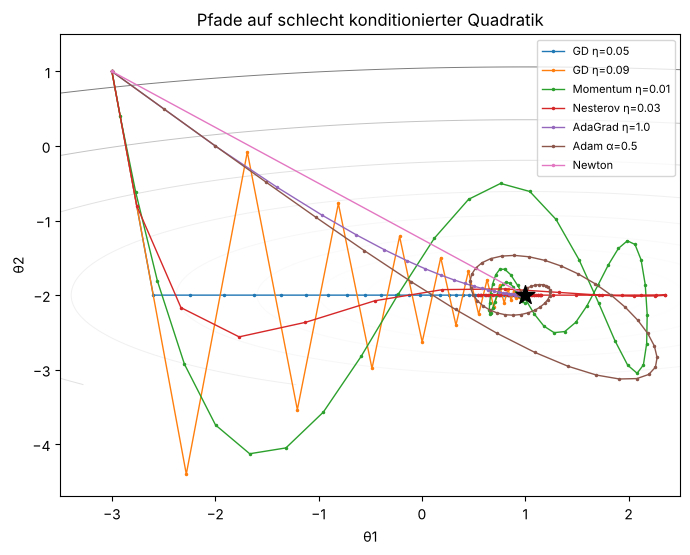

In [4]:
t0, t1 = np.meshgrid(np.linspace(-3.5, 2.5, 200), np.linspace(-3.2, 1.5, 200))
Z = (t0 - 1)**2 + 10 * (t1 + 2)**2
plt.figure(figsize=(8, 6))
plt.contour(t0, t1, Z, levels=np.logspace(-1, 2.2, 15), cmap="Greys", linewidths=0.7)
for k, p in runs.items():
    plt.plot(p[:, 0], p[:, 1], marker=".", markersize=3, linewidth=1, label=k)
plt.scatter([1], [-2], marker="*", s=200, c="k", zorder=5)
plt.legend(fontsize=8); plt.title("Pfade auf schlecht konditionierter Quadratik"); plt.xlabel("θ1"); plt.ylabel("θ2"); plt.show()

**Beobachtungen auf diesem Testproblem** (2D, konvex, achsenparallel – kein allgemeines Ranking!)
- **GD:** Die erlaubte Lernrate wird von der **steilen** Richtung begrenzt ($\eta < 2/20 = 0{,}1$). Mit $\eta = 0{,}05$ bleibt $\theta_1$ in der flachen Richtung zurück; nahe der Grenze ($\eta = 0{,}09$) konvergiert GD gut, aber mit Zickzack in $\theta_2$.
- **Momentum** ($\beta = 0{,}9$) sammelt viel Schwung, **überschießt** und oszilliert gedämpft – mehr Schwung ist nicht automatisch schneller. **Nesterov** korrigiert früher und überschießt deutlich weniger.
- **AdaGrad** ist hier fast ideal: Die Funktion ist achsenparallel, also gleicht die **diagonale Vorkonditionierung** die Konditionierung genau aus.
- **Adam** macht pro Koordinate Schritte der Größe etwa $\alpha$ (fast vorzeichenbasiert) – es nähert sich schnell, „zittert" bei fester Lernrate aber um das Optimum. In der Praxis braucht es einen Lernraten-Schedule.
- **Newton:** exaktes Minimum nach **einem** Schritt.

## 3 · Erste Schritte von AdaGrad und Adam

In [5]:
G, th = np.zeros(2), np.zeros(2)
for t in range(1, 3):
    g = np.array([4.0, 0.5]); G += g * g; step = 0.1 * g / np.sqrt(G + 1e-8)
    print(f"AdaGrad t={t}: G={G}, Schritt={step}")

for g1 in [0.001, 5.0, -100.0]:
    m1, v1 = 0.1 * g1, 0.001 * g1**2
    with_bc = -0.001 * (m1 / 0.1) / np.sqrt(v1 / 0.001 + 1e-8)
    without_bc = -0.001 * m1 / np.sqrt(v1 + 1e-8)
    print(f"Adam g1={g1:>8}: Schritt mit Bias-Korrektur {with_bc:+.6f}, ohne {without_bc:+.6f}")

AdaGrad t=1: G=[16.    0.25], Schritt=[0.1 0.1]
AdaGrad t=2: G=[32.   0.5], Schritt=[0.0707 0.0707]
Adam g1=   0.001: Schritt mit Bias-Korrektur -0.000995, ohne -0.000953
Adam g1=     5.0: Schritt mit Bias-Korrektur -0.001000, ohne -0.003162
Adam g1=  -100.0: Schritt mit Bias-Korrektur +0.001000, ohne +0.003162
